# Visual charter test (F36)

Intent: check that the category palette (Okabe-Ito), the heatmap scale (Mako vs viridis), the risk ramp (YlOrRd) and the
model/reference colours stay readable, including in grayscale, before any catalogue figure is drawn.
All values below are **illustrative values, not results**.

{'Safe': 0.48, 'Safe overall': 0.64, 'Bad weather': 0.64, 'Tandem': 0.56, 'Reckless': 0.44}


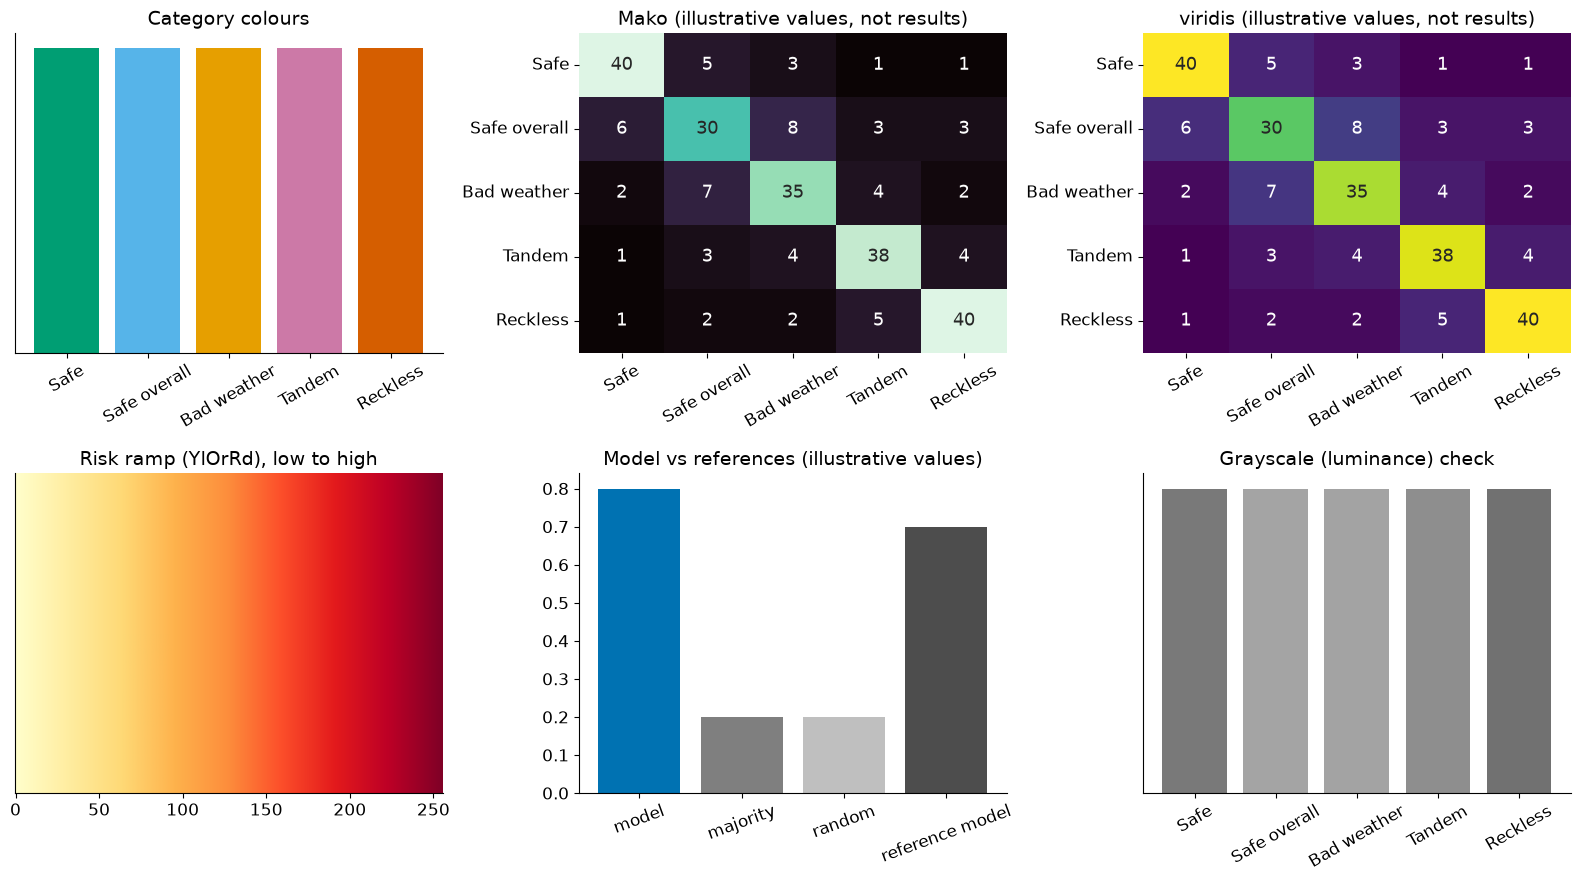

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from ride_classifier.config import LABELS
from ride_classifier.viz.palette import CATEGORY_COLORS, MODEL_COLOR, REFERENCE_COLORS, RISK
from ride_classifier.viz.theme import apply_theme, heatmap_cmap, save_fig
from matplotlib.colors import to_rgb
apply_theme()
cm = np.array([[40,5,3,1,1],[6,30,8,3,3],[2,7,35,4,2],[1,3,4,38,4],[1,2,2,5,40]])
def lum(c):
    r, g, b = to_rgb(c)
    return 0.2126*r + 0.7152*g + 0.0722*b
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
a = ax[0, 0]
a.bar(LABELS, [1]*5, color=list(CATEGORY_COLORS.values())); a.set_yticks([])
a.set_title("Category colours"); a.tick_params(axis="x", rotation=30)
for i, (cmap, name) in enumerate([(heatmap_cmap(), "Mako"), ("viridis", "viridis")]):
    b = ax[0, 1 + i]
    sns.heatmap(cm, cmap=cmap, annot=True, fmt="d", cbar=False, ax=b, xticklabels=LABELS, yticklabels=LABELS)
    b.set_title(f"{name} (illustrative values, not results)"); b.tick_params(axis="x", rotation=30)
a = ax[1, 0]
a.imshow(np.linspace(0, 1, 256)[None, :], aspect="auto", cmap=RISK); a.set_yticks([])
a.set_title("Risk ramp (YlOrRd), low to high")
a = ax[1, 1]
names = ["model", *REFERENCE_COLORS]
a.bar(names, [0.8, 0.2, 0.2, 0.7], color=[MODEL_COLOR, *REFERENCE_COLORS.values()])
a.set_title("Model vs references (illustrative values)"); a.tick_params(axis="x", rotation=20)
a = ax[1, 2]
gray = [lum(c) for c in CATEGORY_COLORS.values()]
a.bar(LABELS, [1]*5, color=[(g, g, g) for g in gray]); a.set_yticks([])
a.set_title("Grayscale (luminance) check"); a.tick_params(axis="x", rotation=30)
fig.tight_layout()
save_fig(fig, "F36", "palette_test")
print({k: round(g, 2) for k, g in zip(LABELS, gray)})

## Decision

Read the Mako matrix against viridis: the diagonal (high counts) is the lightest tone in Mako, so off-diagonal errors
fade into the dark background, while viridis keeps a bright yellow for the maximum that competes with the Reckless/Bad
weather hues. **Recommendation: Mako**, because it is perceptually uniform, prints well in grayscale and does not clash
with the categorical colours. The grayscale row shows Safe overall and Bad weather are close in luminance, so the
labels must always be written next to the colours. (Human review pending.)